##### **学习方式**
![image.png](attachment:9f5ba693-034b-408b-91f0-d7867b34989b.png)
# 第2节. 常见WorkFlow

上一节学习了LangGraph的Node、Edge、State三要素，知道了如何构建Agent，但LangGraph的能力并不在于构建简单的Agent，而是用图的方式灵活编排任意复杂的工作流。

本节深入学习各种常见的流程编排模式。

本节将学习七种核心编排模式：

**左侧两个**：LLM嵌入到了预定义的工作流当中，用于你明确知道工作流程的场景。

**右侧三个**：由LLM来控制工作流，更智能化。

#### **_下述方式它们是在解决“Agent 里面多个任务应该怎么组织、怎么执行”的问题_**

###### **LangGraph = 用 Node、State、Edge 等基础组件，把这些工作流模式（即下述）自由组合起来**
- Prompt Chaining（顺序执行）
- Parallelization（并行执行）
- Routing（路由）
- Orchestrator-Worker + Send API
- Evaluator-Optimizer（评估器-优化器）
- 子图嵌套（Subgraph）
- 总结与选择指南

本章会用到的依赖和工具：


In [2]:
import sys # 处理 Python 运行环境
# Windows 控制台默认 GBK 编码，打印表情/特殊字符会报错，这里统一改用 UTF-8
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
if hasattr(sys.stderr, "reconfigure"):
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")
from typing import Annotated, TypedDict, Literal, List #typing 给 Python 代码加“类型说明”  TypedDict State 本身就经常通过 TypedDict 来定义 Annotated 给一个类型附加额外的信息 Literal  路由 / 固定选项  List 字符串列表
from langgraph.graph import StateGraph, START, END # 创建一个“基于 State 的工作流图” START与END 图的起点和终点
from langgraph.graph.message import add_messages, MessagesState # add_messages 处理消息 “MessageState 专门用于消息对话的现成 State 模板 State
from langgraph.checkpoint.memory import InMemorySaver # Checkpoint / 持久化机制 保存Checkpoint在这里
from langgraph.types import Command, CachePolicy, interrupt, Send # Command：Node 不只是返回 State，还可以控制流程 # CachePolicy 缓存策略，缓存命中  interrupt 用于让 LangGraph 暂停执行，等待外部输入
from langgraph.runtime import Runtime # LangGraph运行环境，提供运行期间信息和能力 例如context runtime stream writer store
from langgraph.types import RetryPolicy, TimeoutPolicy # 这两个主要用于节点执行过程中的可靠性控制  RetryPolicy Node 执行失败以后，要不要重新执行？怎么重新执行？ TimeoutPolicy 一个 Node 最多允许执行多长时间
from langgraph.errors import NodeError # Node 执行错误相关的异常类型
from langchain_core.messages import (
    BaseMessage, SystemMessage, HumanMessage, ToolMessage
) # 导入Langchain消息类型
from langchain.chat_models import init_chat_model # 初始化一个聊天模型
from langchain.tools import tool #将python函数变成LLM可以调用的工具
from IPython.display import Image, display # 在 Notebook 中显示图片
from operator import add # LangGraph 的 State 可以定义聚合规则
from dotenv import load_dotenv # 是一个用于读取 .env 文件的库
from pydantic.dataclasses import dataclass # Pydantic 的 dataclass 可以结合 Pydantic 的数据验证能力  Pydantic 经常被用于定义：State 输入 输出 数据结构 参数验证
from pydantic import BaseModel, Field
import operator # 在 LangGraph 定义 State 的 reducer 时经常能看到它

load_dotenv()

# 把 LangGraph 的结构画出来
def display_graph(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))

llm = init_chat_model("deepseek-chat")
print("依赖导入完成")

依赖导入完成


# 1. 顺序执行（Prompt Chaining）

Prompt Chaining 是最基础的编排模式：前一个LLM的输出作为后一个LLM的输入，像流水线一样串联起来。

**典型场景**: 写作流程（大纲→初稿→润色）、翻译+校对、分步推理。

**与直接 LLM 调用的区别**: 顺序链可以在步骤之间加入验证门控（Gate）——如果某步质量不达标就退回重做，而不是一路到底。

比如，一个写笑话的工作流。


##### **_通常是一个定义好的流程。把一个复杂任务拆成多个步骤，让前一步 LLM 的输出，成为下一步 LLM 的输入，像流水线一样逐步完成任务_**

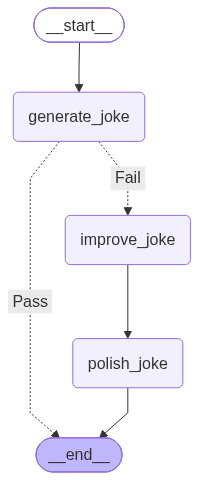

In [3]:
# Prompt Chaining: 生成笑话 → 检查质量 → 润色 → 加梗
# ① 定义数据 → ② 定义每个步骤 → ③ 定义步骤之间怎么连接 → ④ 编译成可执行工作流
from typing import TypedDict #用于定义工作流中传递的数据结构
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field

# 定义了chain中数据怎么流动
class JokeState(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    final_joke: str

# 定义一个LLM节点
def generate_joke(state: JokeState):
    """步骤1: 生成初稿"""
    msg = llm.invoke(f"Write a short joke about {state['topic']}")
    return {"joke": msg.content, "final_joke": msg.content}

# 定义检查步骤 / Gate
def check_punchline(state: JokeState):
    """门控函数: 检查笑话是否有笑点"""
    # 判断刚才生成的笑话质量是否合格
    msg = llm.invoke(
        f"Check if the joke has punchline and wordplay, return 'Pass' or 'Fail' for the joke: ```{state['joke']}```"
    )
    result = msg.content
    if "Pass" in result:
        print(f"  [检查] 通过 ✓")
        return "Pass"
    print(f"  [检查] 不通过 ✗")
    return "Fail"

def improve_joke(state: JokeState):
    """步骤2: 改进——增加双关语"""
    print(f"  [润色] 添加双关语...")
    msg = llm.invoke(f"Make this joke funnier by adding wordplay: {state['joke']}")
    return {"improved_joke": msg.content}

def polish_joke(state: JokeState):
    """步骤3: 润色——加一个反转"""
    print(f"  [润色] 添加反转...")
    msg = llm.invoke(f"Add a surprising twist to this joke: {state['improved_joke']}")
    return {"final_joke": msg.content}

# 构建图 创建一个基于 JokeState 的工作流 这一整块是在 用 LangGraph 把 Prompt Chaining 的流程“编排出来”
chaining_graph = (
    StateGraph(JokeState)
    .add_node("generate_joke", generate_joke)
    .add_node("improve_joke", improve_joke)
    .add_node("polish_joke", polish_joke)
    .add_edge(START, "generate_joke")
    # 条件边：通过则直接结束，不通过则进入改进流程
    .add_conditional_edges(
        "generate_joke",
        check_punchline,
        {"Pass": END, "Fail": "improve_joke"}
    )
    .add_edge("improve_joke", "polish_joke")
    .add_edge("polish_joke", END)
    .compile()
)

# .add_edge() = 固定走哪一步 .add_conditional_edges() = 根据条件决定走哪一步

# 把代码里的工作流画成流程图，方便你看整个 Chain 是怎么连接的
display_graph(chaining_graph)

In [4]:
print("=== 测试1: 话题「大树」 ===\n")
r = chaining_graph.invoke({
    "topic": "大树",
    "joke": "",
    "improved_joke": "",
    "final_joke": ""
})
print(f"\n最终笑话:\n{r['final_joke']}")

=== 测试1: 话题「大树」 ===

  [检查] 通过 ✓

最终笑话:
A programmer was walking through the forest when he saw a **大树** (big tree) crying.  

He asked, “Why are you crying?”  

The tree sobbed, “I just found out I have **no root access**.”


# 2. 并行执行（Parallelization）

通过并行化，可以让多个LLM同时处理一个任务，有两种不同的实现方式和作用：

* **提高效率**: 将任务拆分为子任务，让多个LLM同时运行独立的子任务来完成，再汇总结果
* **提高准确度**: 多个LLM运行相同的任务产生不同的输出，再合并优化结果

比如，我需要同时基于某个话题写三种题材：笑话、故事、诗歌。并行执行的话效率会更高。


######  ****一个任务来了以后，不是让 LLM 一个接一个地做，而是把多个可以同时做的任务一起交给多个 LLM****

##### **Prompt Chaining：一个接一个  Parallelization：同时做**


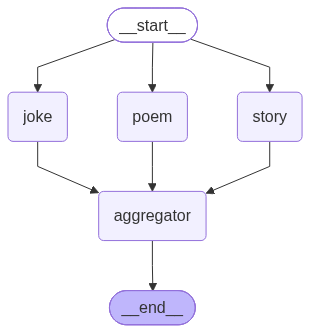

In [5]:
# Graph state 定义整个Graph的状态数据结构
class State(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str

def joke_node(state: State):
    """First LLM call to generate initial joke"""
    msg = llm.invoke(f"Write a joke about {state['topic']}")
    return {"joke": msg.content}

def story_node(state: State):
    """Second LLM call to generate story"""
    msg = llm.invoke(f"Write a short story about {state['topic']}")
    return {"story": msg.content}

def poem_node(state: State):
    """Third LLM call to generate poem"""
    msg = llm.invoke(f"Write a short poem about {state['topic']}")
    return {"poem": msg.content}

# 汇总节点，它等三个并行任务完成后，把结果合在一起
def aggregator(state: State):
    """Combine the joke, story and poem into a single output"""
    combined = f"Here's a story, joke, and poem about {state['topic']}!\n\n"
    combined += f"STORY:\n{state['story']}\n\n"
    combined += f"JOKE:\n{state['joke']}\n\n"
    combined += f"POEM:\n{state['poem']}"
    return {"combined_output": combined}

# 创建一个 LangGraph 工作流
parallel_builder = StateGraph(State)
parallel_builder.add_node("joke", joke_node)
parallel_builder.add_node("story", story_node)
parallel_builder.add_node("poem", poem_node)
parallel_builder.add_node("aggregator", aggregator)

# add_edge指定下一节点  add_conditional_edges 以及Command 根据条件决定下一节点

# 都使用了两个节点，从什么到什么
parallel_builder.add_edge(START, "joke")
parallel_builder.add_edge(START, "story")
parallel_builder.add_edge(START, "poem")
parallel_builder.add_edge("joke", "aggregator")
parallel_builder.add_edge("story", "aggregator")
parallel_builder.add_edge("poem", "aggregator")
parallel_builder.add_edge("aggregator", END)

parallel_workflow = parallel_builder.compile()
display_graph(parallel_workflow)

In [6]:
# Invoke
state = parallel_workflow.invoke({"topic": "程序员"})
print(state["combined_output"])

Here's a story, joke, and poem about 程序员!

STORY:
夜幕像一块浸透墨汁的绒布，沉甸甸地压在写字楼的玻璃幕墙上。二十七层的某扇窗，是这整片墨色里唯一不肯熄灭的光点。

林默坐在办公椅上，脚蹬着桌沿，身体向后倾斜，目光锁在屏幕上闪烁的光标上。咖啡杯沿沾着干涸的褐色印渍，那是昨晚第三杯的遗留物。显示屏的幽光照亮他法令纹深处，那里藏着几天没刮干净的胡茬。

“你在看什么？”我凑过去。

他像是被我吓到似的，肩胛骨猛地一缩，随即又放松。“一个……bug。”他说，“很奇怪。它只在凌晨三点到三点零五分之间出现。”

凌晨三点？我看了看窗外寂静的高速公路，路灯把行道树拉成扭曲的影子。“什么内容？”

“一行代码。”他指着屏幕，“不是我的。准确说，不是任何人的。它会在日志文件里出现，运行一条命令，然后消失。每次都不一样。”

我皱眉。“有人入侵？”

“不。”他推了一下眼镜，镜片映出无数数据流，“查过了，输入是空的。没有外部连接，没有定时任务，没有任何触发条件。它就像……从系统内部自己长出来的。”

“你会读心术吗？”我开玩笑说，“和电脑谈恋爱了？”

他没理我，反而把椅子转过来。“你写过诗吗？”他问，脸上有一种奇怪的热切。

“学生时代写过几首情诗，怎么了？”

“我在想，如果每天都在写代码，写了十年，那些被删除的、被替换的、被注释掉的代码会去哪儿？会不会有某种‘潜意识’？就像人一样，白天被压制的念头晚上会从梦里钻出来。”

“你是在说这个bug是代码的梦？”

他笑了，那是三天以来我第一次见他笑。“我打算今晚一直盯着。看看它到底要干什么。”

凌晨三点零一分，日志刷新。新的一行出现了：

`for (let i = 0; i < 2020; i++) { soul.memory.delete(i); }`

林默的手悬在键盘上方，没有敲击。屏幕光在他的瞳孔里跳动，像微小的火焰。

“这不是命令。”他说，声音里带着一丝颤栗。“这是……忏悔。”

我盯着那几行字符，忽然意识到什么：“你2020年写过一个数据清理工具？用来删除用户资料的？”

他缓缓点头，脸色苍白。“是的，一个金融客户。他们的要求是彻底删除所有痕迹。我写的那些代码，被冠以‘合规’的名义，让几万人的信用记录、交易历史、生活轨迹在一夜之间烟消云散。”

“那你现在……”

“

# 3. 路由（Routing）
###### **_Chaining = 按顺序走_**
###### **_Parallelization = 一起走_**
###### _**Routing = 选路走**_

Routing工作流处理用户输入，然后将它们引导到上下文相关的任务Node。这允许您为复杂的任务定义专门的流。例如：

* 智能电商客服，首先识别问题的类型，然后将请求路由到售前咨询、退款、退货等对应的Node。
* 知识问答机器人，首先识别问题知识领域，然后将请求路由到不同领域对应的专业Node上。

所以路由本质上也是条件分支，让Graph根据问题动态选择下一节点。这是Agent智能决策的核心机制。

##### **区分LangGraph以及Langchain工作流模式**

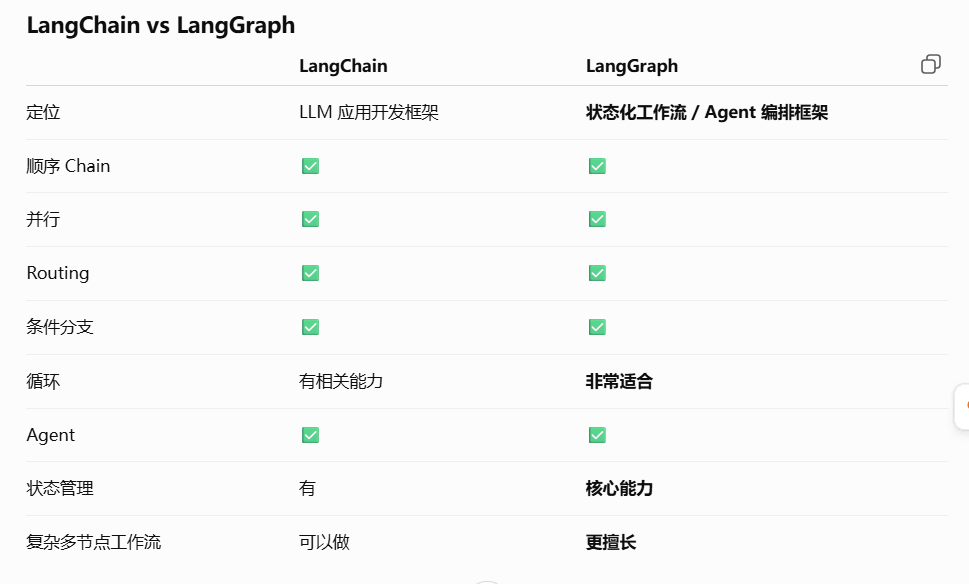


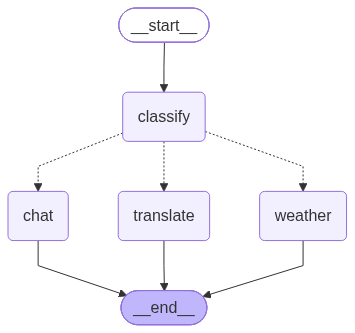

In [7]:
from typing import Literal # 它用来限制一个变量只能取指定的几个值 对于 Router 很重要，因为它定义了：允许路由到哪些地方
from langchain_core.messages import HumanMessage, SystemMessage # 导入两种类型的消息
from pydantic import BaseModel, Field # 用于定义结构化的数据模型 主要是给LLM的输出规定格式

# 定义一个Pydantic，规定router最终必须给我什么格式的结果
class Route(BaseModel):
    # 定义router决策空间
    step: Literal["weather", "translate", "chat"] = Field(
        None, description="The next step in the routing process"
    )

# 创建router 把llm变成能够按照router结构输出结果的LLM 等价于llm
router = llm.with_structured_output(Route)

# 定义state 整个工作流运行过程中共享的数据
class IntentState(TypedDict):
    query: str
    intent: str
    result: str

# 是一个Graph Node，让LLM判断用户意图
def classify_intent(state: IntentState):
    """分类用户意图"""
    decision = router.invoke([
        SystemMessage(content="Route the input to weather, translate, or chat based on the user's request."),
        # 把用户的问题传给 LLM
        HumanMessage(content=state["query"]),
    ])
    return {"intent": decision.step}
# 下面三个是业务处理node
def handle_weather(state: IntentState):
    return {"result": f"天气查询: {state['query']} -> 晴 25度"}

def handle_translate(state: IntentState):
    return {"result": f"翻译: {state['query']} -> Hello World"}

def handle_chat(state: IntentState):
    return {"result": f"闲聊: {state['query']} -> 你好呀！"}

# 读取 State 中的 intent，告诉 Graph 下一步去哪
def intent_router(state: IntentState) -> Literal["weather", "translate", "chat"]:
    """根据意图路由到不同处理器"""
    return state["intent"]

# 构建了一个router工作流
routing_graph = (
    StateGraph(IntentState)
    .add_node("classify", classify_intent)
    .add_node("weather", handle_weather)
    .add_node("translate", handle_translate)
    .add_node("chat", handle_chat)
    .add_edge(START, "classify")
    # 先进入 classify 判断，然后根据判断结果决定下一步去 weather、translate 还是 chat
    .add_conditional_edges("classify", intent_router, {
        "weather": "weather",
        "translate": "translate",
        "chat": "chat"
    })
    .add_edge("weather", END)
    .add_edge("translate", END)
    .add_edge("chat", END)
    .compile()
)

display_graph(routing_graph)

In [8]:
# 测试三种意图
for q in ["今天北京天气如何?", "翻译hello", "你好吗?"]:
    r = routing_graph.invoke({"query": q, "intent": "", "result": ""})
    print(f"'{q}' -> intent={r['intent']} -> {r['result']}")

'今天北京天气如何?' -> intent=weather -> 天气查询: 今天北京天气如何? -> 晴 25度
'翻译hello' -> intent=translate -> 翻译: 翻译hello -> Hello World
'你好吗?' -> intent=chat -> 闲聊: 你好吗? -> 你好呀！


# 4. Orchestrator-Worker + Send API

Orchestrator-Worker，顾名思义，编排器—工作者模型。分为三个步骤：

* **编排器 (Orchestrator)**：将任务分解为子任务，将子任务分配给worker
* **工作节点 (Worker)**：并行执行任务
* **合成器 (Synthesizer)**：将worker的输出汇总为最终结果

**与普通并行的区别**：

* 普通并行工作流：任务是需要手动拆分的，且子任务数量是固定的
* Orchestrator-Worker：用模型动态将复杂任务拆分为多个并行子任务，子任务数量不确定

## 4.1 Send API

通过 **Send API**，你可以动态创建工作节点并向它们发送特定的输入。每个工作节点都有自己的State，所有工作节点的输出都会被写入一个共享的State字段中。

##### **_工作流程：Orchestrator 决定拆什么 → Send 动态创建并行任务 → Worker 执行 → Shared State 收集 → Synthesizer 汇总_**


In [9]:
from typing import Annotated, List # 导入 Annotated 用来给类型增加额外的信息
import operator # 导入operator模块，里面有很多操作函数

# 定义数据模型 是“一个章节/一个子任务的模板
class Section(BaseModel):
    name: str = Field(description="Name for this section of the report.")
    description: str = Field(description="Brief overview of the main topics and concepts to be covered in this section.")
# 多个Section集合 多个章节多个子任务
class Sections(BaseModel):
    sections: List[Section] = Field(description="Sections of the report.")

# 创建一个 Planner，这个 Planner 调用 LLM 时，要求 LLM 按照 Sections 数据结构输出
# 创建了一个带有“输出格式约束”的 LLM 调用器
planner = llm.with_structured_output(Sections)
print("结构化输出模型定义完成")

结构化输出模型定义完成


In [10]:
# State 和 WorkerState 就是在定义“数据在整个工作流中怎么流动、每个节点能看到什么、能读写哪些字段，最终结果放在哪里”
# 编排者的 State 下述每个字段通常主要服务于某类节点
class State(TypedDict):
    topic: str  # 用户输入的主题
    sections: list # 编排者规划出来的章节列表
    completed_sections: Annotated[list, operator.add] # 已经完成的章节内容列表 多个 Worker 并行写完后，会把结果追加到这里
    final_report: str # 最终生成的完整报告

# Worker的State
class WorkerState(TypedDict):
    section: Section # 当前这个 Worker 要负责写的那一个章节
    completed_sections: Annotated[list, operator.add]  # Worker 写完自己的章节后，把结果放进这个字段

print("State定义完成")

State定义完成


In [11]:
# 根据 topic 生成报告的章节计划，写入 sections State
def orchestrator(state: State):
    """Orchestrator that generates a plan for the report"""
    report_sections = planner.invoke([
        SystemMessage(content="Generate a plan for the report."),
        HumanMessage(content=f"Here is the report topic: {state['topic']}"),
    ])
    return {"sections": report_sections.sections}

# 工人节点根据单个 section 写出具体内容，返回到 completed_sections WorkerState
# 负责撰写单个章节
def worker(state: WorkerState):
    """Worker writes a section of the report"""
    section = llm.invoke([
        SystemMessage(content="Write a report section following the provided name and description. Include no preamble for each section. Use markdown formatting."),
        HumanMessage(content=f"Here is the section name: {state['section'].name} and description: {state['section'].description}"),
    ])
    return {"completed_sections": [section.content]}

# 汇总节点把所有已完成的章节拼接成最终报告 final_report State
def synthesizer(state: State):
    """Synthesize full report from sections"""
    completed_sections = state["completed_sections"]
    completed_report_sections = "\n\n---\n\n".join(completed_sections)
    return {"final_report": completed_report_sections}

print("Node定义完成")

Node定义完成


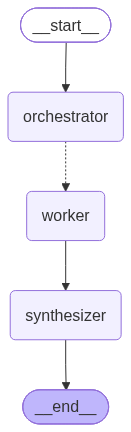

Orchestrator-Worker Graph构建完成


In [12]:
from langgraph.types import Send # 导入send 作用：向某一个 Node 发送一个独立的任务和对应的 State

# 把编排者生成的章节列表，拆分成多个并行任务，分别发给 worker 节点去执行

# 定义一个函数，接收全局state
def assign_workers(state: State):
    """Assign a worker to each section in the plan"""

   # 遍历 state["sections"] 里的每一个章节 s
   # 为每个章节创建一个 Send 对象：
   # "worker"：要发送到的目标节点名称
   # {"section": s}：传给该 worker 的状态（对应 WorkerState 里的 section 字段）
   # 最终返回一个 Send 对象的列表
    return [Send("worker", {"section": s}) for s in state["sections"]]

# orchestrator → worker → synthesizer组装成一个LangGraph工作流
orchestrator_worker_graph = (
    StateGraph(State)
    .add_node("orchestrator", orchestrator)
    .add_node("worker", worker)
    .add_node("synthesizer", synthesizer)
    .add_edge(START, "orchestrator")
    # 从 orchestrator 节点出来后，根据 assign_workers 函数的返回结果，动态决定下一步去哪些节点
    .add_conditional_edges("orchestrator", assign_workers, ["worker"])
    .add_edge("worker", "synthesizer")
    .add_edge("synthesizer", END)
    .compile()
)

display_graph(orchestrator_worker_graph)
print("Orchestrator-Worker Graph构建完成")

In [13]:
print("=== 测试深度研究助手 ===\n")

# 这是在创建一个 多智能体工作流（Multi-Agent Workflow），而不是传统意义上的单个 Agent 启动整个工作流，并传入初始状态
result = orchestrator_worker_graph.invoke({
    "topic": "人工智能在教育中的应用",
    "sections": [],
    "completed_sections": [],
    "final_report": ""
})
print(result["final_report"][:1500] + "\n...(truncated)")

=== 测试深度研究助手 ===

## 引言

人工智能（AI）正以前所未有的速度渗透至社会各领域，教育作为文明传承与人力资本塑造的核心场域，同样站在了技术变革的临界点。从自适应学习平台到智能辅导系统，从自动批改工具到大语言模型驱动的对话式学习助手，AI技术已不再仅是实验室中的概念验证，而是逐步嵌入课堂教学、课程设计与教育治理的日常肌理。这一进程既源于算力、算法与数据资源的指数级增长，也受到全球教育公平、个性化学习与终身教育需求日益迫切的现实驱动。在此背景下，审视AI与教育的关系，绝非单纯的技术乐观主义叙事，而是关乎教育本质、伦理边界与未来人才培养模式的深层拷问。

本报告旨在系统梳理人工智能在教育应用中的现状、潜力与挑战，并在此基础上提出面向高质量发展的路径建议。报告共分为五个部分：第一部分回顾AI教育应用的关键技术演进与典型场景，建立基础认知框架；第二部分聚焦于教学、学习与评价三个核心环节，分析AI如何重塑教与学的互动形态；第三部分转向风险与伦理议题，探讨数据隐私、算法偏见、过度依赖等不可回避的问题；第四部分比较国内外政策与实践案例，提炼可借鉴经验；第五部分则从制度、技术与人文三个维度，构建面向未来的协同治理框架。报告的核心论点是：人工智能不应被视为替代教师的工具，而应作为赋能教育生态的杠杆——其价值实现取决于能否在“技术效率”与“育人温度”之间找到动态平衡，并依赖多方主体共同参与的制度化调适。

我们期待本报告能为教育决策者、实践者与研究者提供兼具洞察力与操作性的参考，亦希望引发更广泛的公众讨论：在智能时代，我们究竟要培养什么样的人，以及如何让技术真正服务于人的全面发展。

---

### 人工智能技术概述

人工智能（Artificial Intelligence, AI）是研究、开发用于模拟、延伸和扩展人类智能的理论、方法、技术及应用系统的一门新兴技术科学。其核心目标在于使计算机能够执行通常需要人类智能才能完成的复杂任务，如视觉感知、语音识别、决策推理和自然语言理解。近年来，随着计算能力的跃升、海量数据的积累以及算法的持续创新，人工智能已从实验室走向大规模产业应用，并逐渐渗透至教育领域，为基础教育变革提供了全新的技术底座。

#### 一、核心关键技术

**1. 机器学习（Machine Learning）**  
机器学习是人工智能的核心分支，其基

# 5. Evaluator-Optimizer（评估器-优化器）

Evaluator-Optimizer 模式形成一个质量提升的闭环：生成 → 评估 → 不达标则带着反馈重写 → 再次评估……直到质量达标。

**与普通循环的区别**：循环自带“质量门”，只在质量不达标时才重复，避免了无谓的循环。

**典型场景**: 文案优化、代码审查、翻译质量提升。


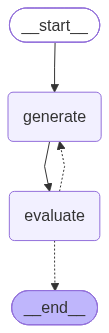

In [14]:
# 生成 → 评估 → 达标就结束，不达标就重新生成 → 再评估
from typing import Literal # 导入Literal 说明一个变量只能是指定的几个值之一

# 定义state   整个广告生成工作流共享的数据
class AdState(TypedDict):
    product: str # 产品名称
    slogan: str # 当前生成的广告语
    feedback: str # Evaluator 给出的修改意见
    grade: str # 广告语是否通过评估
    iteration: int # 当前是第几轮生成
# 定义一个评估节点：检查当前广告语是否符合要求
def evaluator_node(state: AdState):
    """评估广告语质量"""
    slogan = state["slogan"]
    checks = []
    if len(slogan) < 10:
        checks.append("太短了，不够吸引人")
    if state["product"] not in slogan:
        checks.append(f"没有提到产品名'{state['product']}'")
    if "！" not in slogan and "!" not in slogan and "？" not in slogan:
        checks.append("缺少情感标点，不够有感染力")
    if not checks:
        return {"grade": "good", "feedback": ""}
    return {"grade": "bad", "feedback": "；".join(checks)}

# 定义一个生成器 / 优化器节点
def generate_slogan(state: AdState):
    """生成/改进广告语"""
    feedback = state.get("feedback", "")
    iteration = state.get("iteration", 0) + 1
    if feedback:
        print(f"  [第{iteration}轮] 根据反馈改进: {feedback}")
        new_slogan = f"🔥 {state['product']} 好啊！真滴棒！{state['product']} 好啊！顶呱呱！"
    else:
        new_slogan = f"{state['product']} 真好"
        print(f"  [第{iteration}轮] 初版生成: {new_slogan}")
    return {"slogan": new_slogan, "iteration": iteration}

# 定义路由函数 决定下一步往哪里走
def route_after_eval(state: AdState) -> Literal["generate", "__end__"]:
    """评估后路由：good→结束，bad→重新生成，超过3轮强制终止"""
    if state["grade"] == "good":
        print(f"  ✓ 评估通过！最终版本: {state['slogan']}")
        return END
    if state.get("iteration", 0) >= 3:
        print(f"  ⚠ 达到最大迭代次数，强制终止")
        return END
    return "generate"

eval_opt_graph = (
    StateGraph(AdState)
    .add_node("generate", generate_slogan)
    .add_node("evaluate", evaluator_node)
    .add_edge(START, "generate")
    .add_edge("generate", "evaluate")
    # 判断去哪一个节点
    .add_conditional_edges("evaluate",
            route_after_eval, {
        "generate": "generate",
        END: END
    })
    .compile() # 把前面定义好的图（节点 + 边）编译成可执行的 Runnable程序
)

display_graph(eval_opt_graph)

In [ ]:
print("=== 测试广告语生成优化 ===\n")
r = eval_opt_graph.invoke({
    "product": "智能手表",
    "slogan": "",
    "feedback": "",
    "grade": "",
    "iteration": 0
})
print(f"\n最终广告语: {r['slogan']}")
print(f"迭代次数: {r['iteration']}")

# 6. 子图嵌套（Subgraph）

##### **理解为：把一个已经编译好的完整工作流，当作另一个更大工作流里的「一个普通节点」来使用**

当工作流变得过于庞大不利于维护时，可以拆分为多层子图。LangGraph 支持将 **已编译的子图作为父图的一个Node** 直接使用。

| 方式 | API | 特点 |
|------|-----|------|
| 直接嵌入 | `add_node("name", compiled_subgraph)` | 子图作为图节点，checkpoint与父图集成，interrupt自动向上冒泡 |
| 包装调用 | 在普通node函数内 `subgraph.invoke()` | 灵活的状态映射，需手动传递数据 |

若采用嵌入模式，且父图的State与子图的State共享某些key时：

* **父→子**: 父图自动将共享key的值传给子图（input projection）
* **子→父**: 子图返回的key如果父图也有，则按父图的reducer写回


子图编译完成


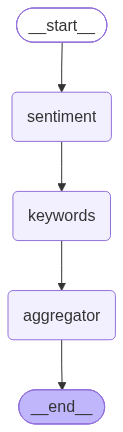

In [15]:
# ========== 方式1: 直接嵌入 compiled subgraph ==========

# 定义父图的状态 父图的全局状态，包含输入文本、中间结果、最终输出等
class ParentState(TypedDict):
    input_text: str
    result: str
    preprocessed: str
    final_output: str

# 定义子图的状态 子图自己的状态。注意 input_text 和 result 与父图同名，这是后续能自动传递数据的关键
class AnalysisSubState(TypedDict):
    input_text: str
    result: str
    sentiment: str
    keywords: str

# 子图的三个节点函数

def detect_sentiment(state: AnalysisSubState):
    """节点1: 检测情感"""
    text = state["input_text"]
    positive_words = ["好", "棒", "喜欢", "赞", "优秀", "nice"]
    score = sum(1 for w in positive_words if w in text)
    sentiment = "正面 😊" if score > 0 else "负面/中性 😐"
    print(f"    [子图-情感分析] sentiment={sentiment}")
    # 返回sentiment字段
    return {"sentiment": sentiment}

def extract_keywords(state: AnalysisSubState):
    """节点2: 提取关键词"""
    text = state["input_text"]
    kw = text[:30] + ("..." if len(text) > 30 else "")
    print(f"    [子图-关键词] keywords={kw}")
    # 返回keywords字段
    return {"keywords": kw}

def sub_aggregator(state: AnalysisSubState):
    """节点3: 合并结果"""
    # 把前面的 sentiment 和 keywords 合并成一句话 写入 result 字段（这个字段会在子图结束后自动回传给父图）
    print(f"    [子图-合并结果] result=..")
    return {"result": f"情感:{state['sentiment']}, 关键词:{state['keywords']}"}
# 构建并编译子图
analysis_subgraph = (
    StateGraph(AnalysisSubState) # 使用子图自己的状态
    .add_node("sentiment", detect_sentiment) # 添加情感分析节点
    .add_node("keywords", extract_keywords) # 添加关键词提取节点
    .add_node("aggregator", sub_aggregator) # 添加结果合并节点
    .add_edge(START, "sentiment")
    .add_edge("sentiment", "keywords")
    .add_edge("keywords", "aggregator")
    .add_edge("aggregator", END)
    .compile() # 编译成可执行的子图
)

print("子图编译完成")
display_graph(analysis_subgraph)


=== 父图结构（子图作为节点）===


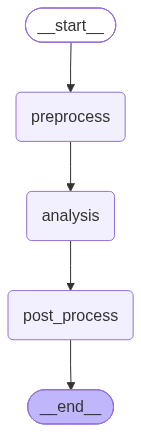


=== XRay模式（展开子图内部）===


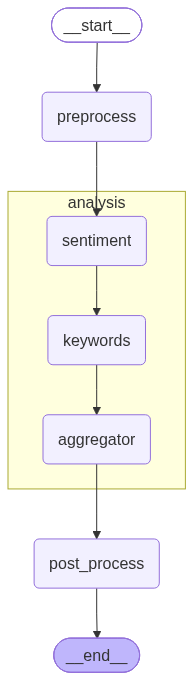

In [16]:
# 父图的两个普通节点

# 父图的预处理节点 读取 input_text，简单处理后写入 preprocessed 字段
def preprocess(state: ParentState):
    print(f"  [父图-预处理] 收到: {state['input_text'][:30]}...")
    return {"preprocessed": state["input_text"]}
# 父图的后处理节点 读取子图返回的 result 字段 包装成最终输出 final_output
def post_process(state: ParentState):
    print(f"  [父图-后处理] 子图结果: {state['result']}")
    return {"final_output": f"✅ 处理完成: {state['result']}"}

parent_graph = (
    StateGraph(ParentState)
    .add_node("preprocess", preprocess)
    # 进入子图时：把父图中与子图 State 同名的字段（input_text）传进去 子图执行完毕后：把子图返回的同名字段（result）写回父图
    .add_node("analysis", analysis_subgraph)  # 直接嵌入已编译子图
    .add_node("post_process", post_process)
    .add_edge(START, "preprocess")
    .add_edge("preprocess", "analysis")
    .add_edge("analysis", "post_process")
    .add_edge("post_process", END)
    .compile()
)

print("\n=== 父图结构（子图作为节点）===")
display_graph(parent_graph)
print("\n=== XRay模式（展开子图内部）===")
display_graph(parent_graph, xray=True)

In [17]:
print("=== 测试直接嵌入子图 ===\n")
r = parent_graph.invoke({
    "input_text": "这个产品真好用，我很喜欢！",
    "result": "",
    "preprocessed": "",
    "final_output": ""
})
print(f"\n最终输出: {r['final_output']}")

=== 测试直接嵌入子图 ===

  [父图-预处理] 收到: 这个产品真好用，我很喜欢！...
    [子图-情感分析] sentiment=正面 😊
    [子图-关键词] keywords=这个产品真好用，我很喜欢！
    [子图-合并结果] result=..
  [父图-后处理] 子图结果: 情感:正面 😊, 关键词:这个产品真好用，我很喜欢！

最终输出: ✅ 处理完成: 情感:正面 😊, 关键词:这个产品真好用，我很喜欢！


## 6.2 包装调用

当父子图State不完全一致时，可以用包装调用方式手动映射状态。


###### 当父图和子图的字段对不上（名字不同、结构不同）时，就不能再依赖自动同步了，需要自己写一个普通节点函数，       在函数内部：
######
###### 从父图状态中取出需要的数据
###### 转换/映射成子图需要的格式
###### 调用 subgraph.invoke(...)
###### 把子图的返回结果再映射回父图状态



=== 包装调用父图结构 ===


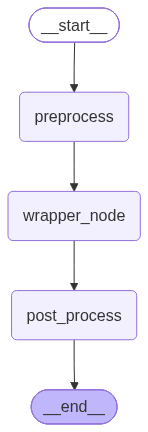

In [18]:
# 定义一个普通的父图节点函数，用于“包装”子图的调用
def wrapper_node(state: ParentState):
    """在普通节点内调用子图，手动映射状态"""
    print(f"  [父图-包装调用] 准备调用子图...")
    # 手动构造子图需要的输入状态  因为是包装调用，必须自己把父图的数据映射成子图 AnalysisSubState 要求的格式。这里把所有字段都补齐了（即使有些是空值）
    sub_input = {
        "input_text": state["input_text"],
        "result": "",
        "sentiment": "",
        "keywords": ""
    }
    # 真正调用子图。 子图会完整跑完自己的流程（情感分析 → 关键词 → 合并），然后返回结果
    sub_result = analysis_subgraph.invoke(sub_input)
    # 手动把子图的结果映射回父图状态。 只取了子图返回的 result，并做了一点包装后写回父图的 result 字段
    return {"result": f"包装调用结果: {sub_result['result']}"}

parent_graph_v2 = (
    StateGraph(ParentState)
    .add_node("preprocess", preprocess)
    .add_node("wrapper_node", wrapper_node)  # 注意：这里加的是包装函数，不是子图本身
    .add_node("post_process", post_process)
    .add_edge(START, "preprocess")
    .add_edge("preprocess", "wrapper_node")
    .add_edge("wrapper_node", "post_process")
    .add_edge("post_process", END)
    .compile()
)

print("\n=== 包装调用父图结构 ===")
display_graph(parent_graph_v2)

In [19]:
print("=== 测试包装调用子图 ===\n")
r = parent_graph_v2.invoke({
    "input_text": "这个产品真好用，我很喜欢！",
    "result": "",
    "preprocessed": "",
    "final_output": ""
})
print(f"\n最终输出: {r['final_output']}")

=== 测试包装调用子图 ===

  [父图-预处理] 收到: 这个产品真好用，我很喜欢！...
  [父图-包装调用] 准备调用子图...
    [子图-情感分析] sentiment=正面 😊
    [子图-关键词] keywords=这个产品真好用，我很喜欢！
    [子图-合并结果] result=..
  [父图-后处理] 子图结果: 包装调用结果: 情感:正面 😊, 关键词:这个产品真好用，我很喜欢！

最终输出: ✅ 处理完成: 包装调用结果: 情感:正面 😊, 关键词:这个产品真好用，我很喜欢！


# 7. 总结

## 七种编排模式速查

###### LangGraph 解决“怎么编排 AI 逻辑”，Dify 解决“怎么快速把 AI 应用做出来、部署和运营”

| 模式 | API | 原理 | 典型场景 |
|------|-----|------|----------|
| **Prompt Chaining** | `add_edge` + `add_conditional_edges` 做门控 | 串联，每个LLM输出作下一个LLM输入，中间可插入质检 | 写作流程、翻译+校对、分步推理 |
| **Routing** | `add_conditional_edges(node, router, mapping)` | router函数返回节点名，mapping映射到实际节点 | 意图路由、权限分流、LLM工具调用判断 |
| **Parallelization** | 多条 `add_edge` 指向不同目标 | 节点间无依赖即可并行，需要reducer合并结果 | 同时查多个数据源、并行LLM调用 |
| **Orchestrator-Worker** | `add_conditional_edges` + **Send API** | 动态生成Send列表，并行分发到同一节点不同State | 批量处理、子问题分解、分布式搜索 |
| **Evaluator-Optimizer** | 条件边回环 + 评估器门控 | 生成→评估→不达标带反馈重写，达标则退出 | 文案优化、代码审查、翻译质量提升 |
| **子图嵌套** | `add_node("name", compiled_subgraph)` 或包装调用 | 子图独立管理内部State和控制流，父图复用完整流程 | 复杂流程分层、可复用流程组件 |

## 核心要点

1. **Prompt Chaining** 是最简单的编排 — 串联LLM调用，中间加入门控检查，形成可验证的流水线
2. **路由是智能的基础** — Agent通过 `add_conditional_edges` 根据State动态选择路径
3. **并行提升性能** — 无依赖的节点可并行执行，用 `operator.add` 等reducer合并结果
4. **Orchestrator-Worker** — 动态任务拆分与并行执行，是智能与效率的结合，需要Send API
5. **Evaluator-Optimizer保障质量** — 生成→评估→反馈→重写循环，直到达标
6. **子图实现分层设计** — 复杂流程拆为独立子图，`add_node(graph)` 直接嵌入，共享State自动映射

## 模式选择指南

* 确定步骤顺序 → **Prompt Chaining**
* 存在不同领域的Node → **智能路由(Routing)**
* 多个独立任务加速 → **并行执行(Parallelization)**
* 复杂任务动态拆分和性能提升 → **Orchestrator-Worker(Send)**
* 需要迭代优化质量 → **Evaluator-Optimizer**
* 流程太长需要拆解 → **子图嵌套**


---

## 本节练习建议

1. 修改 Prompt Chaining 的门控条件，观察不同 Pass/Fail 路径。
2. 在 Parallelization 中增加第四个节点（如“总结”），调整 fan-in。
3. 扩展 Routing 的意图类别，并使用真实工具调用。
4. 用 Orchestrator-Worker 生成一份关于“LangGraph 最佳实践”的短报告。
5. 把 Evaluator-Optimizer 的评估逻辑换成真正的 LLM 结构化输出。
6. 尝试把子图进一步嵌套，观察 xray 视图。
